# pyMPPost on MCNPX-PoliMi collision files → light output

Runs pyMPPost on a set of MCNPX-PoliMi collision files (one file per independent run, e.g. `cf2520.d` … `cf25299.d`)
and combines all the pulses into a single light output histogram.

pyMPPost can be downloaded from: https://gitlab.eecs.umich.edu/umich-dnng/pymppost

The pyMPPost input file (`input_config.toml`) and the material cards are external and edited by hand. The input file
is used as a **template**: for every collision file a temporary copy is written with `polimi_det_in` and `output_root`
replaced, while the template itself is never modified. In the template:

* `NPS` must be the number of source particles of **one** collision file;
* `polimi_det_in` and `output_root` are ignored (they are replaced for each file);
* every other setting (detector cells, material cards, thresholds, resolution…) is used as it is.

In [1]:
import os
import re
import glob
import time
import subprocess

# TOML reader: tomllib (Python >= 3.11) or its backport tomli (Python 3.10)
try:
    import tomllib
except ModuleNotFoundError:
    import tomli as tomllib   # pip install tomli

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# ================================ CONFIGURATION ================================
PARTICLE = "photon"                  # "neutron" | "photon"

# Folder with the pyMPPost TOML files. pyMPPost is run from here, so relative
# paths inside the TOML files (e.g. material cards) are resolved from it.
MPPOST_DIR   = "./"
INPUT_CONFIG = "input_config.toml"    # template; NPS = source particles of ONE file

# MCNPX-PoliMi collision files
COLLISION_DIR     = "/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/results/sodium-iodide/137Cs/MCNPX-PoliMi-simulation-results-NPS1e3"
COLLISION_PATTERN = "cs137*.d"        # glob pattern of the collision files
N_EXPECTED        = 100               # expected number of files (None = no check)

# MCNPX-PoliMi files usually contain both neutron and photon collisions.
# True: pyMPPost only sees the collisions of PARTICLE, as in the OpenMC workflow
#       (no mixed neutron + photon pulses).
# False: pyMPPost sees every collision; pulses are filtered afterwards.
FILTER_PARTICLE = True

RUN_PYMPPOST = True                   # False: only analyse existing pyMPPost outputs
PYMPPOST_EXE = "pyMPPost"             # command used to launch pyMPPost

# Columns of the _All_Pulses files (0-based, negative = from the end)
COL_CELL, COL_PTYPE, COL_LO = 1, 3, -1

# Light output histogram
N_BINS        = 50
LO_MIN        = 0.05                    # [MeVee]
LO_MAX        = 0.8                  # [MeVee]; None = pulse_height.threshold.upper
PER_BIN_WIDTH = False                 # True: counts per source particle per MeVee

# Results
LABEL    = "MCNPX-PoliMi"                     # prefix of the saved keys, e.g. "MCNP-bin-edges"
SAVE_DIR = "/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/results/sodium-iodide/137Cs"
# ===============================================================================

PARTICLE_CODES = {"neutron": 1, "photon": 2}   # MCNPX-PoliMi / pyMPPost particle types
PTYPE = PARTICLE_CODES[PARTICLE]

def resolve(path):
    """Resolve a path from the TOML files relative to MPPOST_DIR."""
    return os.path.normpath(os.path.join(MPPOST_DIR, os.path.expanduser(path)))

def run_index(path):
    """Numeric index at the end of the file name (cf25212.d -> 12), for sorting."""
    m = re.search(r"(\d+)$", os.path.splitext(os.path.basename(path))[0])
    return int(m.group(1)) if m else -1

# --- Read the pyMPPost template ------------------------------------------------
config_path = resolve(INPUT_CONFIG)
with open(config_path, "rb") as f:
    CFG = tomllib.load(f)
with open(config_path) as f:
    CONFIG_TEXT = f.read()            # raw text, used to write the per-file copies

HAS_HEADER     = CFG["i/o"].get("output_headers", True)
NPS_PER_FILE   = int(CFG["detectors"]["NPS"])
DETECTOR_CELLS = CFG["detectors"]["detector_cells"]
LO_THRESHOLD   = (CFG["pulse_height"]["threshold"]["lower"],
                  CFG["pulse_height"]["threshold"]["upper"])

if LO_MAX is None:
    LO_MAX = LO_THRESHOLD[1]
LO_BIN_EDGES = np.linspace(LO_MIN, LO_MAX, N_BINS + 1)

# --- Collision files -------------------------------------------------------------
COLLISION_FILES = sorted(glob.glob(os.path.join(COLLISION_DIR, COLLISION_PATTERN)), key=run_index)
if not COLLISION_FILES:
    raise FileNotFoundError(f"No files matching {COLLISION_PATTERN} in {COLLISION_DIR}")
if N_EXPECTED is not None and len(COLLISION_FILES) != N_EXPECTED:
    print(f"WARNING: found {len(COLLISION_FILES)} collision files, expected {N_EXPECTED}.")

# Every existing file is a completed run, even if empty (no collisions in the detector):
# all of them contribute to the total number of source particles.
NPS_TOTAL = NPS_PER_FILE * len(COLLISION_FILES)

# pyMPPost outputs go in a folder named after the collision folder and the particle
OUTPUT_DIR = os.path.join(MPPOST_DIR, f"pyMPPost_output_{os.path.basename(os.path.normpath(COLLISION_DIR))}_{PARTICLE}")
os.makedirs(os.path.join(OUTPUT_DIR, "logs"), exist_ok=True)

print(f"Template       : {config_path}")
print(f"Collision files: {len(COLLISION_FILES)} ({os.path.basename(COLLISION_FILES[0])} … "
      f"{os.path.basename(COLLISION_FILES[-1])})")
print(f"NPS per file   : {NPS_PER_FILE:.3e}")
print(f"NPS total      : {NPS_TOTAL:.3e}")
print(f"Detector cells : {DETECTOR_CELLS}")
print(f"LO thresholds  : {LO_THRESHOLD} MeVee")
print(f"Output folder  : {OUTPUT_DIR}")

Template       : input_config.toml
Collision files: 100 (cs1370.d … cs13799.d)
NPS per file   : 1.000e+03
NPS total      : 1.000e+05
Detector cells : [[11]]
LO thresholds  : (0.01, 0.8) MeVee
Output folder  : ./pyMPPost_output_MCNPX-PoliMi-simulation-results-NPS1e3_photon


# Step 1: Run pyMPPost on every collision file

In [3]:
def set_toml_string(text, key, value):
    """Replace the string value of ``key`` in the raw TOML text (comments are kept)."""
    new_text, n = re.subn(rf'^(\s*{key}\s*=\s*")[^"]*(")',
                          lambda m: f"{m.group(1)}{value}{m.group(2)}",
                          text, count=1, flags=re.MULTILINE)
    if n != 1:
        raise KeyError(f"'{key}' not found in {config_path}")
    return new_text

def prepare_collision_file(path):
    """
    Return (file for pyMPPost, number of lines kept, particle types found, max history).
    With FILTER_PARTICLE a copy with only the PARTICLE collisions is written in OUTPUT_DIR.
    """
    with open(path) as f:
        lines = [line for line in f if line.strip()]
    types = {int(line.split()[2]) for line in lines}
    max_hist = max((int(line.split()[0]) for line in lines), default=0)
    if not FILTER_PARTICLE:
        return path, len(lines), types, max_hist
    kept = [line for line in lines if int(line.split()[2]) == PTYPE]
    out = os.path.join(OUTPUT_DIR, f"{os.path.basename(path)}.{PARTICLE}")
    with open(out, "w") as f:
        f.writelines(kept)
    return out, len(kept), types, max_hist

def output_root(path):
    """pyMPPost output root of a collision file (cf2520.d -> OUTPUT_DIR/cf2520.mpp)."""
    return os.path.join(OUTPUT_DIR, os.path.splitext(os.path.basename(path))[0] + ".mpp")

if RUN_PYMPPOST:
    tmp_config = os.path.join(MPPOST_DIR, "_tmp_input_config.toml")   # same folder as the template
    skipped, failed, types_found = [], [], set()
    t0 = time.time()

    for k, path in enumerate(COLLISION_FILES):
        name = os.path.basename(path)
        det_in, n_lines, types, max_hist = prepare_collision_file(path)
        types_found |= types

        if max_hist > NPS_PER_FILE:
            print(f"WARNING: {name} has history {max_hist} > NPS per file ({NPS_PER_FILE}).")
        if n_lines == 0:
            skipped.append(name)      # no collisions: counted in NPS_TOTAL, nothing to run
            continue

        # Per-file copy of the template
        text = set_toml_string(CONFIG_TEXT, "polimi_det_in", os.path.abspath(det_in))
        text = set_toml_string(text, "output_root", output_root(path))
        with open(tmp_config, "w") as f:
            f.write(text)

        result = subprocess.run([PYMPPOST_EXE, tmp_config], cwd=MPPOST_DIR,
                                capture_output=True, text=True)
        with open(os.path.join(OUTPUT_DIR, "logs", f"{name}.log"), "w") as f:
            f.write(result.stdout + result.stderr)
        if result.returncode != 0:
            failed.append(name)

        print(f"[{k + 1:>3}/{len(COLLISION_FILES)}] {name:<14} {n_lines:>7} collisions  "
              f"{'FAILED' if result.returncode else 'ok'}")

    os.remove(tmp_config)
    print(f"\nDone in {time.time() - t0:.0f} s. Particle types in the collision files: {sorted(types_found)}")
    if PTYPE not in types_found:
        raise ValueError(f"No collisions of particle type {PTYPE} ({PARTICLE}) were found.")
    if skipped:
        what = f"{PARTICLE} collisions" if FILTER_PARTICLE else "collisions"
        print(f"{len(skipped)} files without {what} (skipped, still counted in NPS).")
    if failed:
        print(f"WARNING: pyMPPost failed on {len(failed)} files (see {OUTPUT_DIR}/logs): {failed}")
else:
    print("RUN_PYMPPOST = False: using the existing outputs.")

[  1/100] cs1370.d          2850 collisions  ok
[  2/100] cs1371.d          2970 collisions  ok
[  3/100] cs1372.d          2816 collisions  ok
[  4/100] cs1373.d          2957 collisions  ok
[  5/100] cs1374.d          2878 collisions  ok
[  6/100] cs1375.d          2927 collisions  ok
[  7/100] cs1376.d          3007 collisions  ok
[  8/100] cs1377.d          2867 collisions  ok
[  9/100] cs1378.d          2902 collisions  ok
[ 10/100] cs1379.d          2829 collisions  ok
[ 11/100] cs13710.d         2874 collisions  ok
[ 12/100] cs13711.d         2936 collisions  ok
[ 13/100] cs13712.d         2871 collisions  ok
[ 14/100] cs13713.d         2913 collisions  ok
[ 15/100] cs13714.d         2891 collisions  ok
[ 16/100] cs13715.d         2895 collisions  ok
[ 17/100] cs13716.d         2851 collisions  ok
[ 18/100] cs13717.d         2915 collisions  ok
[ 19/100] cs13718.d         2836 collisions  ok
[ 20/100] cs13719.d         2759 collisions  ok
[ 21/100] cs13720.d         2920 collisi

# Step 2: Load and combine the pulses

In [4]:
frames, missing = [], []
for path in COLLISION_FILES:
    pulses_file = f"{output_root(path)}_All_Pulses"
    if not os.path.isfile(pulses_file):
        missing.append(os.path.basename(path))   # skipped (empty) or failed run
        continue
    raw = pd.read_csv(pulses_file, sep=r"\s+", header=0 if HAS_HEADER else None)
    if raw.empty:
        continue
    frames.append(pd.DataFrame({
        "run":   run_index(path),
        "cell":  raw.iloc[:, COL_CELL].astype(int).to_numpy(),
        "ptype": raw.iloc[:, COL_PTYPE].astype(int).to_numpy(),
        "lo":    raw.iloc[:, COL_LO].astype(float).to_numpy(),   # light output [MeVee]
    }))

pulses = pd.concat(frames, ignore_index=True)

# Check that COL_CELL, COL_PTYPE and COL_LO point to the right columns
print("All_Pulses columns      :", list(raw.columns))
print(f"Files with pulses       : {len(frames)} / {len(COLLISION_FILES)}")
print(f"Files without output    : {len(missing)}")
print(f"Pulses                  : {len(pulses)}")
print("Pulses per particle type:", pulses["ptype"].value_counts().to_dict())
print("Pulses per cell         :", pulses["cell"].value_counts().to_dict())

All_Pulses columns      : ['history', 'cell', 'pulse', 'particle_type', 'mat_num', 'time', 'light']
Files with pulses       : 100 / 100
Files without output    : 0
Pulses                  : 86854
Pulses per particle type: {2: 86854}
Pulses per cell         : {11: 86854}


# Step 3: Light output histograms

det0  : 84994 pulses in [0.05, 0.8] MeVee
total : 84994 pulses in [0.05, 0.8] MeVee


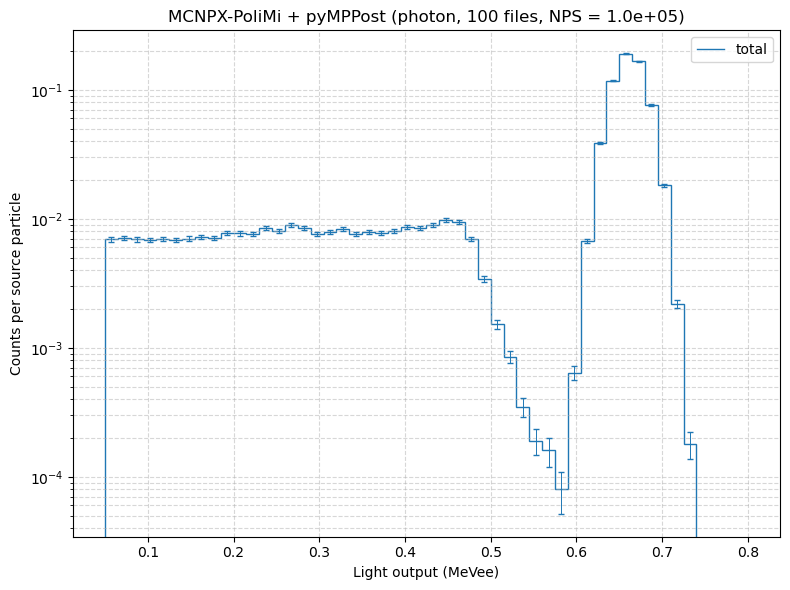

In [5]:
def lo_histogram(lo):
    """Light output histogram normalised per source particle, with Poisson errors."""
    counts, edges = np.histogram(lo, bins=LO_BIN_EDGES)
    norm = NPS_TOTAL * (np.diff(edges) if PER_BIN_WIDTH else 1.0)
    return {"bin_edges": edges,
            "bin_centers": 0.5 * (edges[:-1] + edges[1:]),
            "counts": counts,
            "counts_norm": counts / norm,
            "counts_err_norm": np.sqrt(counts) / norm}

# Keep only pulses of the analysed particle
sel = pulses[pulses["ptype"] == PTYPE]

# One histogram per detector (as grouped in detector_cells) plus the total
hists = {f"det{d}": lo_histogram(sel.loc[sel["cell"].isin(cells), "lo"])
         for d, cells in enumerate(DETECTOR_CELLS)}
all_cells = [c for cells in DETECTOR_CELLS for c in cells]
hists["total"] = lo_histogram(sel.loc[sel["cell"].isin(all_cells), "lo"])

for name, h in hists.items():
    print(f"{name:<6}: {h['counts'].sum()} pulses in [{LO_MIN}, {LO_MAX}] MeVee")

# --- Plot -----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
to_plot = list(hists) if len(DETECTOR_CELLS) > 1 else ["total"]
for name in to_plot:
    h = hists[name]
    step = ax.stairs(h["counts_norm"], h["bin_edges"], label=name)
    mask = h["counts"] > 0          # empty bins are not drawn on a log scale
    ax.errorbar(h["bin_centers"][mask], h["counts_norm"][mask],
                yerr=h["counts_err_norm"][mask], fmt="none",
                ecolor=step.get_edgecolor(), elinewidth=0.7, capsize=2)

ax.set_title(f"MCNPX-PoliMi + pyMPPost ({PARTICLE}, {len(COLLISION_FILES)} files, NPS = {NPS_TOTAL:.1e})")
ax.set_xlabel("Light output (MeVee)")
ax.set_ylabel("Counts per source particle" + (" per MeVee" if PER_BIN_WIDTH else ""))
ax.set_yscale("log")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

# Step 4: Save

In [6]:
data = dict()

# Total histogram, same keys as before
tot = hists["total"]
data[f"{LABEL}-bin-edges"]       = tot["bin_edges"]
data[f"{LABEL}-bin-centers"]     = tot["bin_centers"]
data[f"{LABEL}-counts-norm"]     = tot["counts_norm"]
data[f"{LABEL}-counts-err-norm"] = tot["counts_err_norm"]

# Per-detector histograms and run information
data[f"{LABEL}-detectors"] = {k: v for k, v in hists.items() if k != "total"}
data[f"{LABEL}-metadata"]  = {"particle": PARTICLE,
                              "filter_particle": FILTER_PARTICLE,
                              "nps_per_file": NPS_PER_FILE,
                              "nps_total": NPS_TOTAL,
                              "collision_files": [os.path.basename(p) for p in COLLISION_FILES],
                              "detector_cells": DETECTOR_CELLS,
                              "per_bin_width": PER_BIN_WIDTH,
                              "input_config": config_path, "mppost_config": CFG}

os.makedirs(SAVE_DIR, exist_ok=True)
save_path = os.path.join(SAVE_DIR, f"{LABEL}_LO_histogram_{PARTICLE}.joblib")
joblib.dump(data, save_path)
print(f"Saved: {save_path}")

Saved: /Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/results/sodium-iodide/137Cs/MCNPX-PoliMi_LO_histogram_photon.joblib
